# 01 — Exploratory data analysis of the training data

## 1. Purpose and data source

**What:** a first look at the labelled training data before any modelling.
**Why:** class balance, sentence length and vocabulary shape the choice of features,
evaluation metrics and baselines, and the numbers here are reported in the presentation.

**Data:** *Financial PhraseBank* (Malo et al., 2014), obtained from Kaggle
("Sentiment Analysis for Financial News", file `all-data.csv`). Each row is one sentence
from English financial news, labelled *negative*, *neutral* or *positive*.

> Malo, P., Sinha, A., Korhonen, P., Wallenius, J., & Takala, P. (2014). Good debt or bad debt:
> Detecting semantic orientations in economic texts. *Journal of the Association for Information
> Science and Technology*, 65(4), 782–796.

This notebook only describes the data: no train/test split and no model.

In [1]:
# Imports and shared settings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.feature_extraction.text import CountVectorizer

from newsentiment import config
from newsentiment.data import load_training_data
from newsentiment.plotting import TEXT_COLOR, apply_style, save_figure

apply_style()                                # common figure style for the project
pd.set_option("display.max_colwidth", None)  # show full sentences in tables
LABELS = list(config.LABELS)                 # fixed class order: negative, neutral, positive
summary = {}                                 # collects every number saved to eda_summary.json

## 2. Load and clean

**What:** load `all-data.csv` with `load_training_data()`, which strips whitespace, removes empty
texts, removes every row of a sentence that carries conflicting labels, and drops exact duplicates.
**Why:** all later numbers must describe the data the model will actually be trained on.

In [2]:
# Load the cleaned data and the cleaning report
df, report = load_training_data()

# Show the report as a small two-column table (class counts follow in section 3)
report_table = pd.DataFrame(
    [(k, v) for k, v in report.items() if k != "class_counts"], columns=["item", "value"]
)
summary["cleaning"] = report
report_table

,item,value
0,rows_in,4846
1,empty_removed,0
2,conflicting_texts,2
3,conflicting_rows_removed,4
4,duplicate_rows_removed,6
5,rows_out,4836


## 3. Class distribution

**What:** number and share of sentences per class, and the share of the largest class.
**Why:** an imbalanced class distribution affects which metrics are meaningful (accuracy vs.
macro-F1) and sets the accuracy of the trivial majority-class baseline.

In [3]:
# Counts and shares (%) per class, in LABELS order
counts = df["label"].value_counts().reindex(LABELS)
shares = counts / counts.sum() * 100
class_table = pd.DataFrame({"count": counts, "share_pct": shares.round(1)})

majority_class = counts.idxmax()
majority_share = float(shares.max())

summary["class_distribution"] = {
    "counts": {k: int(v) for k, v in counts.items()},
    "shares_pct": {k: round(float(v), 2) for k, v in shares.items()},
    "majority_class": majority_class,
    "majority_share_pct": round(majority_share, 2),
}
print(f"Total sentences: {counts.sum():,}")
print(f"Majority class: {majority_class} ({majority_share:.1f} %)")
class_table

Total sentences: 4,836
Majority class: neutral (59.4 %)


,count,share_pct
label,,
negative,604,12.5
neutral,2871,59.4
positive,1361,28.1


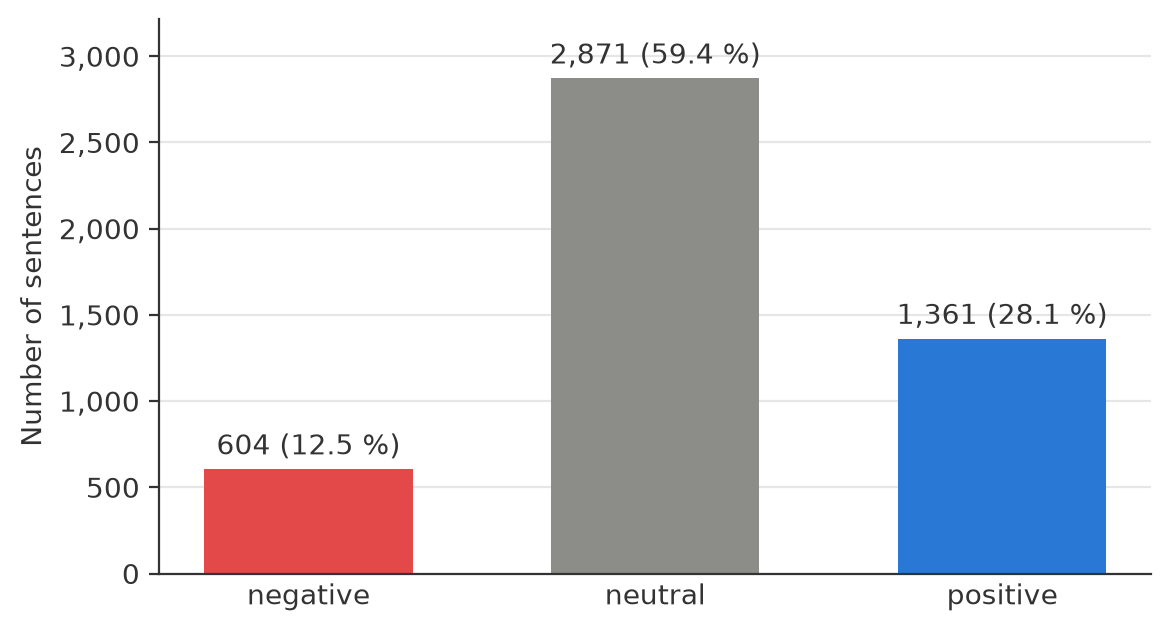

In [4]:
# Bar chart of the class distribution, one colour per class
fig, ax = plt.subplots()
bars = ax.bar(
    LABELS, counts.values, width=0.6, color=[config.CLASS_COLORS[c] for c in LABELS]
)

# Label above each bar: "n (x.x %)"
for bar, n, pct in zip(bars, counts.values, shares.values):
    ax.annotate(
        f"{n:,} ({pct:.1f} %)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 3), textcoords="offset points",
        ha="center", va="bottom", color=TEXT_COLOR,
    )

ax.set_ylabel("Number of sentences")
ax.yaxis.set_major_formatter("{x:,.0f}")  # thousands separator, as in the bar labels
ax.set_ylim(0, counts.max() * 1.12)  # headroom for the labels
ax.tick_params(axis="x", length=0)   # class names without tick marks

# Save (this closes the figure) and display the saved PNG
fig_path = save_figure(fig, "fig_class_distribution")
display(Image(filename=str(fig_path)))

## 4. Sentence length

**What:** length of each sentence in words (split on whitespace), summarised per class and overall.
**Why:** shows how much text the model gets per example and whether length differs between classes.

In [5]:
# Words per sentence (whitespace split)
df["n_words"] = df["text"].str.split().str.len()


def length_stats(s: pd.Series) -> dict:
    '''Count, mean, median, min and max of a length series as plain Python numbers.'''
    return {
        "count": int(s.count()),
        "mean": round(float(s.mean()), 2),
        "median": float(s.median()),
        "min": int(s.min()),
        "max": int(s.max()),
    }


length_summary = {c: length_stats(df.loc[df["label"] == c, "n_words"]) for c in LABELS}
length_summary["overall"] = length_stats(df["n_words"])
summary["sentence_length_words"] = length_summary

pd.DataFrame(length_summary).T

,count,mean,median,min,max
negative,604.0,23.92,22.0,5.0,56.0
neutral,2871.0,22.15,21.0,2.0,81.0
positive,1361.0,24.68,23.0,5.0,57.0
overall,4836.0,23.09,21.0,2.0,81.0


## 5. Vocabulary

**What:** size of the vocabulary under scikit-learn's default `CountVectorizer` tokenisation
(lowercased, tokens of two or more word characters, **no** stop-word removal), and the share of
distinct tokens that occur only once in the whole corpus.
**Why:** a large share of one-off tokens means many features carry almost no training signal.

In [6]:
# Token counts per sentence with default tokenisation, lowercase, no stop-word removal
vectorizer = CountVectorizer(lowercase=True)
X = vectorizer.fit_transform(df["text"])
vocab = vectorizer.get_feature_names_out()

# Total occurrences of each token across all sentences
token_totals = np.asarray(X.sum(axis=0)).ravel()

n_distinct = int(len(vocab))
n_once = int((token_totals == 1).sum())
summary["vocabulary"] = {
    "total_tokens": int(token_totals.sum()),
    "distinct_tokens": n_distinct,
    "tokens_occurring_once": n_once,
    "share_occurring_once_pct": round(n_once / n_distinct * 100, 2),
}
pd.Series(summary["vocabulary"], name="value").to_frame()

,value
total_tokens,96410.00
distinct_tokens,10067.00
tokens_occurring_once,5121.00
share_occurring_once_pct,50.87


## 6. Distinctive words per class

**What:** for every token that occurs at least 20 times (no stop-word removal), its *lift* per class:

$$\text{lift}(t, c) = \frac{\text{share of the occurrences of } t \text{ that fall in class } c}{\text{share of all tokens that fall in class } c}$$

A lift of 1 means the token is as frequent in the class as expected; 2 means twice as frequent.
The 10 tokens with the highest lift per class are listed with their total count.
**Why:** shows which words carry class information, as a sanity check for a bag-of-words model.

In [7]:
MIN_COUNT = 20

# Token counts per class: rows = classes (LABELS order), columns = tokens
class_token_counts = np.vstack(
    [np.asarray(X[(df["label"] == c).to_numpy()].sum(axis=0)).ravel() for c in LABELS]
)

# Share of all tokens that fall in each class
class_token_share = class_token_counts.sum(axis=1) / class_token_counts.sum()

# Keep only frequent tokens, then compute the lift for each class
frequent = token_totals >= MIN_COUNT
share_in_class = class_token_counts[:, frequent] / token_totals[frequent]
lift = share_in_class / class_token_share[:, None]

top10 = {}
tables = []
for i, c in enumerate(LABELS):
    # Highest lift first; ties (e.g. tokens found in one class only) broken by higher count
    order = np.lexsort((-token_totals[frequent], -lift[i].round(6)))[:10]
    top = pd.DataFrame({
        "token": vocab[frequent][order],
        "count": token_totals[frequent][order].astype(int),
        "lift": lift[i][order].round(2),
    })
    top10[c] = [
        {"token": str(t), "count": int(n), "lift": float(l)}
        for t, n, l in top.itertuples(index=False)
    ]
    tables.append(top.add_prefix(f"{c}_"))

summary["distinctive_words"] = {
    "min_count": MIN_COUNT,
    "n_tokens_considered": int(frequent.sum()),
    "class_token_share_pct": {
        c: round(float(s) * 100, 2) for c, s in zip(LABELS, class_token_share)
    },
    "top10": top10,
}
print(f"Tokens with count >= {MIN_COUNT}: {frequent.sum():,}")
pd.concat(tables, axis=1)

Tokens with count >= 20: 723


,negative_token,negative_count,negative_lift,neutral_token,neutral_count,neutral_lift,positive_token,positive_count,positive_lift
0,decreased,79,6.72,www,29,1.75,improved,21,3.35
1,down,98,6.61,square,25,1.75,grew,34,3.25
2,fell,55,6.53,details,24,1.75,won,34,3.15
3,lay,31,5.79,disclosed,24,1.75,rose,102,3.08
4,lower,40,5.66,espoo,20,1.75,awarded,35,3.06
5,off,46,5.09,headquartered,32,1.69,positive,28,2.99
6,cut,26,4.80,no,53,1.68,respectively,24,2.93
7,items,31,4.78,any,26,1.68,increased,109,2.73
8,offs,20,4.68,analysis,25,1.68,liters,20,2.68
9,temporary,20,4.68,tikkurila,24,1.67,improve,22,2.58


## 7. Examples

**What:** three randomly drawn sentences per class (fixed seed for reproducibility).
**Why:** gives a concrete feel for the texts and labels behind the numbers above.

In [8]:
# Three random sentences per class, reproducible via the project seed
examples = pd.concat(
    [df.loc[df["label"] == c, ["label", "text"]].sample(3, random_state=config.RANDOM_SEED)
     for c in LABELS]
).set_index("label")
examples

,text
label,
negative,The company decided at the end of 2008 to temporarily shut down its ammonia plant in Billingham and extend the maintenance period at its Ince facility .
negative,down to EUR5 .9 m H1 '09 3 August 2009 - Finnish media group Ilkka-Yhtyma Oyj ( HEL : ILK2S ) said today its net profit fell 45 % on the year to EUR5 .9 m in the first half of 2009 .
negative,"The steelmaker said that the drop in profit was explained by the continuing economic uncertainty , mixed with the current drought in bank lending , resulting in a decline in demand for its products as customers find it increasingly difficult to fund operations ."
neutral,The total project duration is three years and it is valued at some EUR11 .5 m.
neutral,"Upon establishment , the plan is directed to approximately 20 persons ."
neutral,"The company 's US subsidiary Vaisala Inc. acquires Aviation Systems Maintenance , Inc ASMI , a Kansas , U.S. based airport service company with over 2.6 million USD net sales in 2008 ."
positive,"Shares of Standard Chartered ( STAN ) rose 1.2 % in the FTSE 100 , while Royal Bank of Scotland ( RBS ) shares rose 2 % and Barclays shares ( BARC ) ( BCS ) were up 1.7 % ."
positive,"It projected revenue of $ 2.2 billion to $ 2.3 billion , slightly higher than analyst estimates of $ 2.19 billion ."
positive,Technical indicators for the stock are bullish and S&P gives NOK a positive 4 STARS out of 5 buy ranking .


In [9]:
# Save all numbers from sections 2-6
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
summary_path = config.METRICS_DIR / "eda_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(f"Saved {summary_path.relative_to(config.PROJECT_ROOT).as_posix()}")

Saved outputs/metrics/eda_summary.json


## 8. Observations

Measured values only; all numbers are saved in `outputs/metrics/eda_summary.json`.

- **Cleaning:** 4,846 rows in; 0 empty texts, 2 texts with conflicting labels (4 rows) and
  6 exact duplicates removed; **4,836 sentences** remain.
- **Class distribution:** negative 604 (12.5 %), neutral 2,871 (59.4 %), positive 1,361 (28.1 %).
  The majority class is *neutral* with 59.4 %, which is the accuracy of always predicting neutral.
  Neutral has 4.8 times as many sentences as negative.
- **Sentence length (words):** mean 23.1, median 21, range 2–81 overall. Means per class:
  negative 23.9, neutral 22.2, positive 24.7.
- **Vocabulary:** 96,410 tokens, 10,067 distinct tokens; 5,121 of them (50.9 %) occur only once.
- **Distinctive words** (723 tokens with count ≥ 20):
  - negative: highest lifts 4.7–6.7 (*decreased*, *down*, *fell*, *lay*, *lower*, *off*, *cut*);
  - positive: highest lifts 2.6–3.4 (*improved*, *grew*, *won*, *rose*, *awarded*, *increased*);
  - neutral: highest lift 1.75, the maximum possible for this class (1 / 0.573), reached by
    5 tokens that occur only in neutral sentences (*www*, *square*, *details*, *disclosed*, *espoo*).